<center><h1>Last_First_HW7</h1></center>

Name: 
<br>
Github Username: 
<br>
USC ID: 

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv("Frogs_MFCCs.csv")
display(df.head())
print("Dataset shape :", df.shape)

,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


Dataset shape : (7195, 26)


In [3]:
X = df.drop(columns = ["Family", "Genus", "Species", "RecordID"])
y = df[["Family", "Genus", "Species"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.7, random_state = 42)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (5036, 22)
X_test : (2159, 22)
y_train : (5036, 3)
y_test : (2159, 3)


### (b) Train a classifier for each label

#### (i) Research

- **Exact match:** The proportion of samples with all three labels predicted correctly.
- **Average Hamming distance:** The mean number of incorrectly predicted labels per sample, ranging from 0 to 3 here.
- **Hamming loss:** The proportion of incorrectly predicted labels across the three output columns. It equals the average Hamming distance divided by 3.
- **Hamming score:** Defined here as 1 − Hamming loss.

Higher exact match and Hamming score, and lower Hamming distance
and Hamming loss, indicate better performance.

#### (ii) Train a SVM for each of the labels

In [4]:
param_grid = {"estimator__C": [0.1, 1, 10, 100, 1000, 10000], "estimator__gamma": [0.01, 0.1, 1, 10]}

cv = StratifiedKFold(n_splits = 10, shuffle = True, random_state = 42)

In [5]:
rbf_models = {}
rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_results = []

for label in y_train.columns:
    model = OneVsRestClassifier(SVC(kernel="rbf"))

    search = GridSearchCV(estimator = model, param_grid = param_grid,scoring = "accuracy",cv = cv,n_jobs = -1)

    search.fit(X_train, y_train[label])

    rbf_models[label] = search.best_estimator_
    rbf_predictions[label] = search.predict(X_test)

    rbf_results.append({"Label": label,"Best C": search.best_params_["estimator__C"], "Best gamma" : search.best_params_["estimator__gamma"], "CV accuracy" : search.best_score_})

    print(label, "completed")

display(pd.DataFrame(rbf_results))

Family completed
Genus completed
Species completed


,Label,Best C,Best gamma,CV accuracy
0,Family,1000,1,0.991659
1,Genus,10,1,0.991064
2,Species,10,1,0.990074


In [6]:
correct = y_test.to_numpy() == rbf_predictions.to_numpy()

exact_match = np.mean(np.all(correct, axis=1))
hamming_loss_value = np.mean(~correct)
hamming_score = np.mean(correct)

print("Exact match:", exact_match)
print("Hamming loss:", hamming_loss_value)
print("Hamming score:", hamming_score)

Exact match: 0.9874942102825383
Hamming loss: 0.0077196232823838196
Hamming score: 0.9922803767176162


Using raw features and 10-fold cross-validation, the best (C, gamma)
values within the search grid were (1000, 1) for Family and (10, 1)
for both Genus and Species.  
The test exact match ratio was 0.9875, Hamming loss was 0.0077,
and Hamming score was 0.9923.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [7]:
l1_param_grid = {"svm__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)
l1_results = []

for label in y_train.columns:
    model = Pipeline([("scaler", StandardScaler()), ("svm", LinearSVC(penalty = "l1", dual = False, max_iter = 1000000, random_state = 42))])

    search = GridSearchCV(estimator = model, param_grid = l1_param_grid, scoring = "accuracy", cv = cv, n_jobs = -1)

    search.fit(X_train, y_train[label])

    l1_models[label] = search.best_estimator_
    l1_predictions[label] = search.predict(X_test)

    l1_results.append({"Label" : label, "Best C" : search.best_params_["svm__C"], "CV accuracy" : search.best_score_})

    print(label, "completed")

display(pd.DataFrame(l1_results))

Family completed
Genus completed
Species completed


,Label,Best C,CV accuracy
0,Family,10,0.941223
1,Genus,1000,0.951750
2,Species,10,0.960682


In [8]:
l1_correct = y_test.to_numpy() == l1_predictions.to_numpy()

l1_exact_match = np.mean(np.all(l1_correct, axis=1))
l1_hamming_loss = np.mean(~l1_correct)
l1_hamming_score = np.mean(l1_correct)

print("Exact match:", l1_exact_match)
print("Hamming loss:", l1_hamming_loss)
print("Hamming score:", l1_hamming_score)

Exact match: 0.9124594719777674
Hamming loss: 0.05697081982399259
Hamming score: 0.9430291801760075


After standardization, 10-fold cross-validation selected C = 10
for Family and Species, and C = 1000 for Genus within the search grid.  
The test exact match ratio was 0.9125, Hamming loss was 0.0570,
and Hamming score was 0.9430. The L1-penalized linear SVM
performed worse than the Gaussian SVM in this experiment.  
For Genus, the selected C = 1000 is at the upper boundary of
the search grid. Its CV accuracy increased only slightly,
from 0.951551 at C = 100 to 0.951750 at C = 1000.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [9]:
smote_models = {}
smote_predictions = pd.DataFrame(index=y_test.index)
smote_results = []

for label in y_train.columns:
    model = ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state = 42)), ("svm", LinearSVC( penalty = "l1", dual = False, max_iter = 100000, random_state = 42))])

    search = GridSearchCV(estimator = model, param_grid = l1_param_grid, scoring = "accuracy", cv = cv, n_jobs = 1)

    search.fit(X_train, y_train[label])

    smote_models[label] = search.best_estimator_
    smote_predictions[label] = search.predict(X_test)

    smote_results.append({"Label" : label, "Best C" : search.best_params_["svm__C"], "CV accuracy" : search.best_score_})

    print(label, "completed")

display(pd.DataFrame(smote_results))

Family completed
Genus completed
Species completed


,Label,Best C,CV accuracy
0,Family,10,0.923156
1,Genus,1,0.912837
2,Species,10,0.958103


In [10]:
smote_correct = y_test.to_numpy() == smote_predictions.to_numpy()

smote_exact_match = np.mean(np.all(smote_correct, axis=1))
smote_hamming_loss = np.mean(~smote_correct)
smote_hamming_score = np.mean(smote_correct)

print("Exact match:", smote_exact_match)
print("Hamming loss:", smote_hamming_loss)
print("Hamming score:", smote_hamming_score)

Exact match: 0.8536359425660027
Hamming loss: 0.07688744789254284
Hamming score: 0.9231125521074571


In [11]:
comparison = pd.DataFrame({"Model" : ["Gaussian SVM", "L1 SVM", "SMOTE + L1 SVM"], 
                           "Exact match": [exact_match, l1_exact_match, smote_exact_match],
                           "Hamming loss": [hamming_loss_value, l1_hamming_loss, smote_hamming_loss],
                           "Hamming score": [hamming_score, l1_hamming_score, smote_hamming_score]})

display(comparison)

,Model,Exact match,Hamming loss,Hamming score
0,Gaussian SVM,0.987494,0.007720,0.992280
1,L1 SVM,0.912459,0.056971,0.943029
2,SMOTE + L1 SVM,0.853636,0.076887,0.923113


With SMOTE, 10-fold cross-validation selected C = 10 for Family
and Species, and C = 1 for Genus within the search grid.  
The test exact match ratio was 0.8536, Hamming loss was 0.0769,
and Hamming score was 0.9231. SMOTE did not improve these overall
metrics compared with the L1 SVM without SMOTE.  
Among the three methods, the Gaussian SVM achieved the best
performance on all three evaluation metrics.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [12]:
X_cluster = X.to_numpy()

cluster_runs = []
kmeans_results = []

for run in range(50):
    best_score = -np.inf
    best_k = None
    best_labels = None

    for k in range(2, 51):
        model = KMeans(n_clusters = k, n_init = 10, random_state = run)

        cluster_labels = model.fit_predict(X_cluster)

        score = calinski_harabasz_score(X_cluster, cluster_labels)

        if score > best_score:
            best_score = score
            best_k = k
            best_labels = cluster_labels.copy()

    cluster_runs.append(best_labels)

    kmeans_results.append({"Run" : run + 1, "Best k" : best_k, "CH score" : best_score})

    print(f"Run {run + 1}/50 completed: best k = {best_k}")

kmeans_results = pd.DataFrame(kmeans_results)
display(kmeans_results)

Run 1/50 completed: best k = 2
Run 2/50 completed: best k = 2
Run 3/50 completed: best k = 2
Run 4/50 completed: best k = 2
Run 5/50 completed: best k = 2
Run 6/50 completed: best k = 2
Run 7/50 completed: best k = 2
Run 8/50 completed: best k = 2
Run 9/50 completed: best k = 2
Run 10/50 completed: best k = 2
Run 11/50 completed: best k = 2
Run 12/50 completed: best k = 2
Run 13/50 completed: best k = 2
Run 14/50 completed: best k = 2
Run 15/50 completed: best k = 2
Run 16/50 completed: best k = 2
Run 17/50 completed: best k = 2
Run 18/50 completed: best k = 2
Run 19/50 completed: best k = 2
Run 20/50 completed: best k = 2
Run 21/50 completed: best k = 2
Run 22/50 completed: best k = 2
Run 23/50 completed: best k = 2
Run 24/50 completed: best k = 2
Run 25/50 completed: best k = 2
Run 26/50 completed: best k = 2
Run 27/50 completed: best k = 2
Run 28/50 completed: best k = 2
Run 29/50 completed: best k = 2
Run 30/50 completed: best k = 2
Run 31/50 completed: best k = 2
Run 32/50 complet

,Run,Best k,CH score
0,1,2,3680.741349
1,2,2,3680.741349
2,3,2,3680.741349
3,4,2,3680.741349
4,5,2,3680.741349
5,6,2,3680.741349
6,7,2,3680.741349
7,8,2,3680.741349
8,9,2,3680.741349
9,10,2,3680.741349


K-means was applied to all 22 raw MFCC features using the entire
dataset. In each of 50 runs, k was selected by maximizing the
Calinski–Harabasz score over k = 2, ..., 50. The case k = 1 was
excluded because the CH score is undefined for a single cluster.  
Each run used a different random seed and n_init = 10.

### (b) Determine which family is the majority

In [13]:
majority_tables = []
cluster_predictions = []

for cluster_labels in cluster_runs:
    label_data = y.copy()
    label_data["Cluster"] = cluster_labels

    majority = label_data.groupby("Cluster")[["Family", "Genus", "Species"]].agg(lambda column: column.mode().iloc[0])

    predictions = majority.loc[cluster_labels].to_numpy()

    majority_tables.append(majority)
    cluster_predictions.append(predictions)

display(majority_tables[0])

,Family,Genus,Species
Cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [14]:
clustering_results = []

for run, predictions in enumerate(cluster_predictions):
    incorrect = y.to_numpy() != predictions

    hamming_distance = np.mean(np.sum(incorrect, axis = 1))
    hamming_loss = np.mean(incorrect)
    cluster_hamming_score = 1 - hamming_loss

    clustering_results.append({"Run" : run + 1, "Average Hamming distance" : hamming_distance, "Hamming loss" : hamming_loss, "Hamming score" : cluster_hamming_score})

clustering_results = pd.DataFrame(clustering_results)

display(clustering_results.head())

,Run,Average Hamming distance,Hamming loss,Hamming score
0,1,0.895622,0.298541,0.701459
1,2,0.895622,0.298541,0.701459
2,3,0.895622,0.298541,0.701459
3,4,0.895622,0.298541,0.701459
4,5,0.895622,0.298541,0.701459


In [15]:
metrics = ["Average Hamming distance", "Hamming loss", "Hamming score"]

summary = clustering_results[metrics].agg(["mean", "std"])

display(summary)

,Average Hamming distance,Hamming loss,Hamming score
mean,8.956220e-01,2.985407e-01,7.014593e-01
std,1.121495e-16,5.607473e-17,1.121495e-16


Across 50 runs, the mean average Hamming distance was 0.8956,
the mean Hamming loss was 0.2985, and the mean Hamming score
was 0.7015, with standard deviations approximately zero.  
All 50 runs selected k = 2 using the CH criterion.
The near-zero standard deviations indicate little variation
across these runs, rather than high clustering accuracy.  
With only two clusters, at most two species labels can be assigned.
The Hamming metrics measure how closely the cluster-based labels
match the known labels.

## 3. ISLR 12.6.2

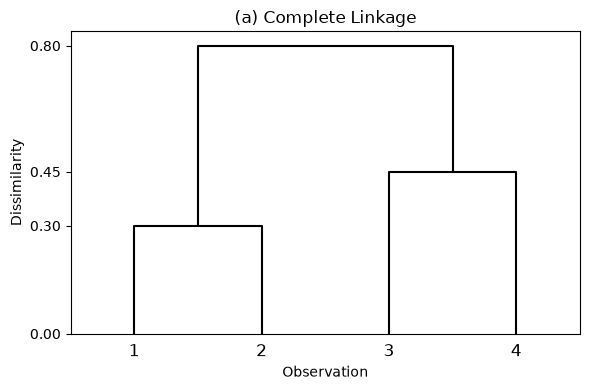

In [16]:
distances = np.array([0.3, 0.4, 0.7, 0.5, 0.8, 0.45])

complete_linkage = linkage(distances, method = "complete")

plt.figure(figsize=(6, 4))

dendrogram(complete_linkage, labels = ["1", "2", "3", "4"], color_threshold = 0, above_threshold_color = "black")

plt.title("(a) Complete Linkage")
plt.xlabel("Observation")
plt.ylabel("Dissimilarity")
plt.yticks([0, 0.3, 0.45, 0.8])
plt.tight_layout()
plt.show()

### (a) Complete linkage

Observations 1 and 2 merge at height 0.30.
Observations 3 and 4 merge at height 0.45.
The two clusters {1, 2} and {3, 4} merge at height 0.80.

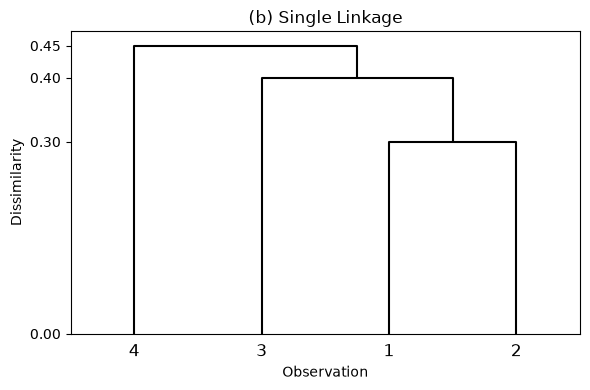

In [17]:
single_linkage = linkage(distances, method = "single")

plt.figure(figsize = (6, 4))

dendrogram(single_linkage, labels = ["1", "2", "3", "4"], color_threshold = 0, above_threshold_color = "black")

plt.title("(b) Single Linkage")
plt.xlabel("Observation")
plt.ylabel("Dissimilarity")
plt.yticks([0, 0.3, 0.4, 0.45])
plt.tight_layout()
plt.show()

### (b) Single linkage

Observations 1 and 2 merge at height 0.30.
Cluster {1, 2} merges with observation 3 at height 0.40.
Cluster {1, 2, 3} merges with observation 4 at height 0.45.

### (c)
Cutting the complete-linkage dendrogram at height 0.60 gives
two clusters: {1, 2} and {3, 4}.

### (d)
Cutting the single-linkage dendrogram at height 0.425 gives
two clusters: {1, 2, 3} and {4}.

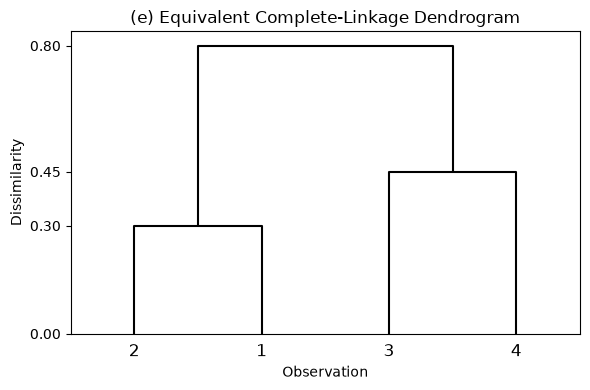

In [18]:
swapped_linkage = complete_linkage.copy()
swapped_linkage[0, [0, 1]] = swapped_linkage[0, [1, 0]]

plt.figure(figsize=(6, 4))

dendrogram(swapped_linkage, labels = ["1", "2", "3", "4"], color_threshold = 0, above_threshold_color = "black")

plt.title("(e) Equivalent Complete-Linkage Dendrogram")
plt.xlabel("Observation")
plt.ylabel("Dissimilarity")
plt.yticks([0, 0.3, 0.45, 0.8])
plt.tight_layout()
plt.show()

### (e)

Swapping leaves 1 and 2 gives the order 2, 1, 3, 4.
The dendrogram remains equivalent to (a) because all cluster
memberships and merge heights remain unchanged.